# 05 · Fusión y re-ranking
Fase 5 del plan: combinar todas las señales (recompra, co-compra, similitud visual, ALS y popularidad)
en un **score ponderado**, ajustar los pesos con validación y dejar lista la función `recommend()` que usará el chat.

**Inputs:** salidas de `01_eda`, `02_baselines`, `03_embeddings`, `04_complementary` y el dataset de la competencia
(solo para mostrar imágenes). **Internet → On** (descarga Fashion-CLIP para codificar consultas). No necesita GPU.

El sistema tiene **dos modos** que comparten las mismas señales y pesos:
- **(a) Cliente:** historial del cliente → compras de la semana siguiente. Es el único medible con MAP@12, así que aquí
  se eligen y ajustan los pesos. Las "anclas" son las últimas compras del cliente.
- **(b) Consulta:** imagen y/o texto → prendas similares + complementarias. Es lo que usa el chat (Fase 6).
  Las "anclas" son los artículos del catálogo más parecidos a la prenda subida.

**Salida:** `weights.json` (pesos del modo a), `ranking_results.csv` (tabla comparativa), `available.parquet` (catálogo disponible).

In [1]:
import os, glob, json, time
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from transformers import CLIPModel, CLIPProcessor

KAGGLE = os.path.exists("/kaggle/input")
def find(name):
    """Busca un archivo en los Inputs del notebook (Kaggle) o en data/ (local)."""
    hits = glob.glob(f"{'/kaggle/input' if KAGGLE else 'data'}/**/{name}", recursive=True)
    assert hits, f"No encontré {name}: agrega como Input el notebook que lo genera"
    return Path(hits[0])

DATA = Path("/kaggle/input/competitions/h-and-m-personalized-fashion-recommendations")  # imágenes
OUT = Path("/kaggle/working") if KAGGLE else Path("data/05-ranking-output")
OUT.mkdir(parents=True, exist_ok=True)

def knn(Q, E, k, chunk=1024):
    """Top-k de E por producto punto para cada fila de Q → (scores, índices), ordenados de mayor a menor."""
    Q = np.atleast_2d(Q)
    S_all, I_all = [], []
    for s in range(0, len(Q), chunk):
        S = Q[s:s + chunk] @ E.T
        I = np.argpartition(-S, k, axis=1)[:, :k]
        Sk = np.take_along_axis(S, I, 1)
        o = np.argsort(-Sk, axis=1)
        S_all.append(np.take_along_axis(Sk, o, 1)); I_all.append(np.take_along_axis(I, o, 1))
    return np.concatenate(S_all), np.concatenate(I_all)

In [2]:
articles = pd.read_parquet(find("articles.parquet"))
train = pd.read_parquet(find("train_small.parquet"))
val = pd.read_parquet(find("val.parquet"))

row = pd.Series(np.arange(len(articles)), index=articles.article_id)   # article_id → fila (entero)
AID = articles.article_id.to_numpy()
PCODE = articles.product_code.to_numpy()
PGROUP = articles.product_group_name.to_numpy()
train["i"] = row.loc[train.article_id].to_numpy()
val["i"] = row.loc[val.article_id].to_numpy()

# Embeddings (03): matriz alineada con `articles` (filas sin imagen = 0)
emb = np.zeros((len(articles), 512), np.float32)
emb[row.loc[pd.read_parquet(find("emb_ids.parquet")).article_id].to_numpy()] = np.load(find("img_emb.npy"))

# ALS (02): factores alineados con `articles` (artículos sin factor = 0)
item_f = np.zeros((len(articles), 128), np.float32)
item_f[row.loc[pd.read_parquet(find("als_items.parquet")).article_id].to_numpy()] = np.load(find("als_item_factors.npy"))
user_f = np.load(find("als_user_factors.npy"))
user_pos = pd.Series(np.arange(len(user_f)), index=pd.read_parquet(find("als_users.parquet")).customer_id)

# Co-compras y complementos (04)
cop_tbl = pd.read_parquet(find("copurchase.parquet"))
comp_tbl = pd.read_parquet(find("complements.parquet"))
for t in (cop_tbl, comp_tbl):
    t["a"] = row.loc[t.anchor_id].to_numpy(); t["b"] = row.loc[t.article_id].to_numpy()
print("Listo:", len(articles), "artículos,", len(train), "transacciones,", len(cop_tbl), "pares de co-compra")

Listo: 105542 artículos, 3664080 transacciones, 1347881 pares de co-compra


## Catálogo disponible y popularidad
El dataset no trae inventario, así que **disponible = vendido en las últimas 4 semanas de train** (≈29k artículos,
cubren ~96 % de las compras de validación). Solo se recomiendan artículos disponibles y con imagen.

In [3]:
END = train.t_dat.max()
recent = train[train.t_dat > END - pd.Timedelta(weeks=4)]
AVAIL = np.intersect1d(recent.i.unique(), np.flatnonzero(emb.any(1)))
is_avail = np.zeros(len(articles), bool); is_avail[AVAIL] = True

last_week = train[train.t_dat > END - pd.Timedelta(days=7)]
counts = last_week.i.value_counts()
POP = np.zeros(len(articles), np.float32); POP[counts.index] = counts.to_numpy() / counts.max()
top12 = counts.index[:12].tolist()   # mismo fallback que en 02
print("Disponibles:", len(AVAIL))

Disponibles: 28966


## Métricas (idénticas a 02) y partición de clientes
Los pesos se ajustan con la **mitad A** de los clientes de validación y la tabla final se reporta en la **mitad B**,
para no medir sobre los mismos datos con los que se ajustó.

In [4]:
def apk(actual, predicted, k=12):
    if not actual:
        return 0.0
    predicted = predicted[:k]
    hits, score, seen = 0, 0.0, set()
    for i, p in enumerate(predicted):
        if p in actual and p not in seen:
            hits += 1
            score += hits / (i + 1)
        seen.add(p)
    return score / min(len(actual), k)

def evaluate(preds, gt, k=12):
    """preds: dict cliente -> lista de artículos; gt: dict cliente -> set de artículos."""
    maps, recs = [], []
    for c, actual in gt.items():
        p = preds.get(c, [])
        maps.append(apk(actual, p, k))
        recs.append(len(actual & set(p[:k])) / len(actual))
    return {"MAP@12": np.mean(maps), "recall@12": np.mean(recs)}

def fill(lst, k=12):
    out = list(dict.fromkeys(lst))[:k]
    out += [a for a in top12 if a not in out][:k - len(out)]
    return out

gt = val.groupby("customer_id").i.agg(set).to_dict()
custs = np.array(list(gt), dtype=np.uint64)   # dtype explícito: los ids no caben en int64 y numpy los volvería float
np.random.default_rng(42).shuffle(custs)
gt_A = {c: gt[c] for c in custs[: len(custs) // 2]}
gt_B = {c: gt[c] for c in custs[len(custs) // 2:]}
print("Clientes de validación:", len(gt), "→ A:", len(gt_A), "B:", len(gt_B))

Clientes de validación: 68984 → A: 34492 B: 34492


## Modo (a): candidatos por cliente
Para cada cliente de validación con historial en train:

| Señal | Candidatos | Valor |
|---|---|---|
| `rep` recompra | todo lo que compró | Σ 1/(1+días desde cada compra) |
| `cop` co-compra (04) | top-10 co-comprados de sus 5 anclas | Σ peso_ancla · score coseno |
| `sim` similitud visual (03) | top-10 visualmente similares (disponibles) de sus 5 anclas | Σ peso_ancla · coseno |
| `als` ALS (02) | top-20 de ALS (disponibles) | producto punto usuario·artículo |
| `pop` popularidad | top-12 de la última semana | ventas / máximo |

Anclas = sus 5 artículos con mayor `rep`, con peso `rep / máx`. Cada señal se normaliza a [0, 1] **dentro de cada cliente**
(las escalas no son comparables) y el score final es `Σ wₛ · señalₛ`. Clientes sin historial → popularidad (como en 02).

In [5]:
N_ANCHORS, K_NEIGH, K_ALS = 5, 10, 20
t0 = time.time()

H = train[train.customer_id.isin(gt)]
hist = (H.assign(rep=1 / (1 + (END - H.t_dat).dt.days))
         .groupby(["customer_id", "i"], as_index=False).rep.sum())
anchors = hist.sort_values("rep", ascending=False).groupby("customer_id").head(N_ANCHORS)
anchors = anchors.assign(aw=anchors.rep / anchors.groupby("customer_id").rep.transform("max"))[["customer_id", "i", "aw"]]

def from_anchors(neigh, name):
    """neigh: tabla (a, b, valor) → Σ peso_ancla · valor por (cliente, b)."""
    m = anchors.merge(neigh, left_on="i", right_on="a")
    return (m.assign(**{name: m.aw * m.value}).groupby(["customer_id", "b"], as_index=False)[name].sum()
             .rename(columns={"b": "i"}))

cop_neigh = cop_tbl[cop_tbl["rank"] < K_NEIGH].rename(columns={"score": "value"})[["a", "b", "value"]]
cand_cop = from_anchors(cop_neigh, "cop")

ua = anchors.i.unique()
ua = ua[emb[ua].any(1)]
s, nn = knn(emb[ua], emb[AVAIL], K_NEIGH + 1)
sim_neigh = pd.DataFrame({"a": np.repeat(ua, K_NEIGH + 1), "b": AVAIL[nn.ravel()], "value": s.ravel()})
sim_neigh = sim_neigh[sim_neigh.a != sim_neigh.b]
cand_sim = from_anchors(sim_neigh, "sim")

known = np.array([c for c in gt if c in user_pos.index], dtype=np.uint64)
als_rows = []
for s0 in range(0, len(known), 2000):
    cs = known[s0:s0 + 2000]
    sc, ix = knn(user_f[user_pos.loc[cs].to_numpy()], item_f[AVAIL], K_ALS)
    als_rows.append(pd.DataFrame({"customer_id": np.repeat(cs, K_ALS), "i": AVAIL[ix.ravel()]}))
cand_als = pd.concat(als_rows)

cand_pop = pd.DataFrame({"customer_id": np.repeat(hist.customer_id.unique(), 12),
                         "i": np.tile(top12, hist.customer_id.nunique())})

cand = (pd.concat([hist, cand_cop, cand_sim, cand_als, cand_pop])
          .groupby(["customer_id", "i"], as_index=False)[["rep", "cop", "sim"]].sum())

# ALS y popularidad como features para TODOS los candidatos (no solo los que ellos generaron)
u = user_pos.reindex(cand.customer_id).to_numpy()
ok = ~np.isnan(u)
U, I = u[ok].astype(int), cand.i.to_numpy()[ok]
cand["als"] = 0.0
cand.loc[ok, "als"] = np.concatenate([np.einsum("ij,ij->i", user_f[U[s:s + 500_000]], item_f[I[s:s + 500_000]])
                                      for s in range(0, len(U), 500_000)])   # por bloques: ~7M filas × 128 no caben de golpe
cand["pop"] = POP[cand.i]

FEATS = ["rep", "cop", "sim", "als", "pop"]
g = cand.groupby("customer_id")
for f in ["rep", "cop", "sim"]:
    cand[f] = (cand[f] / g[f].transform("max")).fillna(0)
mn, mx = g.als.transform("min"), g.als.transform("max")
cand["als"] = ((cand.als - mn) / (mx - mn)).fillna(0)
print(f"{len(cand):,} candidatos para {cand.customer_id.nunique():,} clientes ({time.time() - t0:.0f}s)")

4,969,796 candidatos para 49,219 clientes (35s)


In [6]:
truth = val[["customer_id", "i"]].drop_duplicates()
covered = truth.merge(cand[["customer_id", "i"]].assign(hit=1), how="left").hit.notna().mean()
known_truth = truth[truth.customer_id.isin(hist.customer_id)]
covered_known = known_truth.merge(cand[["customer_id", "i"]].assign(hit=1), how="left").hit.notna().mean()
print(f"Recall de candidatos (techo del re-ranking): {covered:.1%} de todas las compras de validación, "
      f"{covered_known:.1%} de las de clientes con historial")

Recall de candidatos (techo del re-ranking): 8.4% de todas las compras de validación, 11.7% de las de clientes con historial


In [7]:
def predict(w, c=cand, k=12):
    s = c[FEATS].to_numpy() @ np.array([w.get(f, 0) for f in FEATS], np.float32)
    top = c.assign(s=s)[s > 0].sort_values(["customer_id", "s"], ascending=[True, False]).groupby("customer_id").head(k)
    return top.groupby("customer_id").i.agg(list).to_dict()

def run(w, gt_split):
    c = cand[cand.customer_id.isin(gt_split)]
    p = predict(w, c)
    return evaluate({cu: fill(p.get(cu, [])) for cu in gt_split}, gt_split)

## Ajuste de pesos (mitad A)
Ascenso por coordenadas: se fija `rep = 1` como escala y se prueba cada peso en una rejilla, dos pasadas.

In [8]:
GRID = [0, 0.05, 0.1, 0.25, 0.5, 1, 2]
W = {"rep": 1.0, "cop": 0.5, "sim": 0.5, "als": 0.5, "pop": 0.5}
best = run(W, gt_A)["MAP@12"]
t0 = time.time()
for _ in range(2):
    for f in ["cop", "sim", "als", "pop"]:
        for v in GRID:
            m = run({**W, f: v}, gt_A)["MAP@12"]
            if m > best:
                best, W = m, {**W, f: v}
    print("pesos:", W, f"MAP@12(A) = {best:.5f}")
print(f"{time.time() - t0:.0f}s")
json.dump(W, open(OUT / "weights.json", "w"), indent=2)

pesos: {'rep': 1.0, 'cop': 0.25, 'sim': 0.25, 'als': 0.25, 'pop': 0.5} MAP@12(A) = 0.02783
pesos: {'rep': 1.0, 'cop': 0.25, 'sim': 0.1, 'als': 0.25, 'pop': 0.5} MAP@12(A) = 0.02792
231s


## Resultados y ablación (mitad B, nunca vista al ajustar)
- Baselines de 02 recalculados en la mitad B (para comparar en los mismos clientes).
- **Solo X:** solo esa señal (+ popularidad para completar 12).
- **Fusión sin X:** qué se pierde al quitar cada señal.

In [9]:
recent_lists = (train.sort_values("t_dat", ascending=False).drop_duplicates(["customer_id", "i"])
                     .groupby("customer_id").i.agg(list))
rows = {
    "02 · Popularidad (última semana)": evaluate({c: top12 for c in gt_B}, gt_B),
    "02 · Recompra + popularidad": evaluate({c: fill(recent_lists.get(c, [])) for c in gt_B}, gt_B),
}
names = {"rep": "recompra", "cop": "co-compra", "sim": "similitud visual", "als": "ALS", "pop": "popularidad"}
for f in ["rep", "cop", "sim", "als"]:
    rows[f"Solo {names[f]}"] = run({f: 1}, gt_B)
rows["Fusión (pesos ajustados)"] = run(W, gt_B)
for f in FEATS:
    rows[f"Fusión sin {names[f]}"] = run({**W, f: 0}, gt_B)

results = pd.DataFrame(rows).T
results.to_csv(OUT / "ranking_results.csv")
results.style.format("{:.4f}")

,MAP@12,recall@12
02 · Popularidad (última semana),0.0085,0.0253
02 · Recompra + popularidad,0.0261,0.0529
Solo recompra,0.0260,0.0530
Solo co-compra,0.0132,0.0350
Solo similitud visual,0.0052,0.0165
Solo ALS,0.0150,0.0373
Fusión (pesos ajustados),0.0281,0.0610
Fusión sin recompra,0.0141,0.0429
Fusión sin co-compra,0.0275,0.0580
Fusión sin similitud visual,0.0280,0.0605


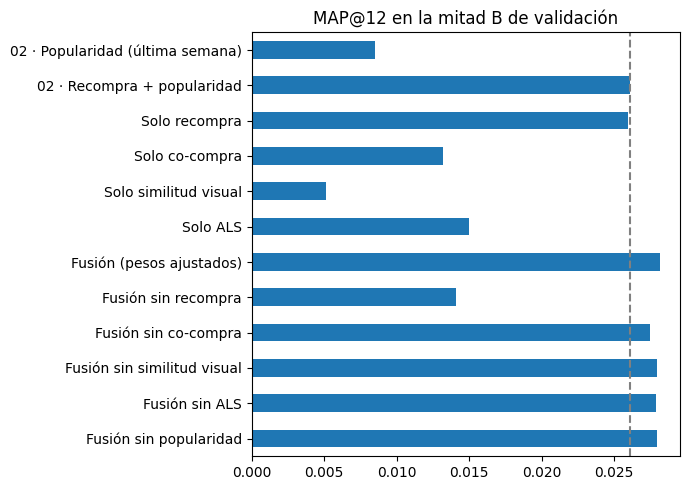

In [10]:
ax = results["MAP@12"].iloc[::-1].plot.barh(figsize=(7, 5), title="MAP@12 en la mitad B de validación")
ax.axvline(results.loc["02 · Recompra + popularidad", "MAP@12"], ls="--", c="gray")
plt.tight_layout(); plt.show()

## Modo (b): `recommend()` para el chat
1. La consulta (imagen, texto o ambos) se codifica con Fashion-CLIP; imagen + texto = suma normalizada de los dos
   vectores (p. ej. foto de un vestido + *"red"* → vestidos parecidos en rojo).
2. **Similares:** artículos disponibles más cercanos a la consulta.
3. **Anclas:** los 3 más cercanos *sin filtros* (lo que "es" la prenda subida) → sus **complementos** del 04.
4. Re-ranking: la señal principal de cada lista (`sim` para similares, `cop` para complementos) + popularidad
   + ALS si se pasa un `customer_id`. Ojo: aquí **no** se usan los pesos `W` del modo (a). Esos se ajustaron para
   predecir recompras (MAP@12) y pueden dejar `sim` casi en 0, lo que en el chat ordenaría los "similares" por
   popularidad. Como el modo consulta no tiene ground truth, la señal principal manda y `WQ` solo desempata;
   se ajusta con la evaluación cualitativa de la Fase 8.
5. Filtros de negocio: solo disponibles, un artículo por `product_code` y `filters` opcionales sobre columnas de `articles`.

Las consultas de texto deben ir **en inglés** (Fashion-CLIP se entrenó en inglés): la capa del LLM (Fase 6) debe traducir.

In [11]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model = CLIPModel.from_pretrained("patrickjohncyh/fashion-clip").to(device).eval()
proc = CLIPProcessor.from_pretrained("patrickjohncyh/fashion-clip")

def as_tensor(out):
    return out if torch.is_tensor(out) else out.pooler_output   # compatibilidad transformers 4 / 5

@torch.no_grad()
def embed_query(image=None, text=None):
    """Vector normalizado de la consulta. image: PIL.Image o ruta; text: str en inglés. Igual preprocesado que en 03."""
    v = torch.zeros(512, device=device)
    if image is not None:
        img = Image.open(image) if isinstance(image, (str, Path)) else image
        x = proc.image_processor(ImageOps.pad(img.convert("RGB"), (224, 224), color="white"), return_tensors="pt")
        v += torch.nn.functional.normalize(as_tensor(model.get_image_features(pixel_values=x["pixel_values"].to(device))), dim=-1)[0]
    if text:
        t = proc.tokenizer([text], padding=True, truncation=True, max_length=77, return_tensors="pt").to(device)
        v += torch.nn.functional.normalize(as_tensor(model.get_text_features(**t)), dim=-1)[0]
    assert v.any(), "Pasa image y/o text"
    return torch.nn.functional.normalize(v, dim=0).cpu().numpy()

WQ = {"pop": 0.1, "als": 0.2}   # pesos del modo consulta (la señal principal pesa 1)
E_AVAIL = emb[AVAIL]
META = articles[["article_id", "prod_name", "product_type_name", "product_group_name", "colour_group_name",
                 "index_group_name", "section_name", "detail_desc"]]

def minmax(x):
    x = np.asarray(x, np.float32)
    return (x - x.min()) / (x.max() - x.min()) if x.max() > x.min() else np.ones_like(x)

def recommend(image=None, text=None, filters=None, customer_id=None, k=6, n_anchors=3):
    """
    Recomendaciones para el chat.
      image: PIL.Image o ruta · text: consulta en inglés · filters: {columna de articles: [valores permitidos]},
      p. ej. {"colour_group_name": ["Black"], "index_group_name": ["Menswear"]} · customer_id: opcional (ALS).
    Devuelve (DataFrame, latencias). El DataFrame tiene `tipo` ('similar' | 'complemento'), score, las señales
    que lo explican (sim, cop, pop, als), `ancla` (para complementos: con qué artículo combina) y metadatos.
    """
    lat, t = {}, time.perf_counter()
    q = embed_query(image, text)
    lat["embedding"] = time.perf_counter() - t; t = time.perf_counter()

    sims = E_AVAIL @ q
    ok = np.ones(len(AVAIL), bool)
    for col, vals in (filters or {}).items():
        ok &= np.isin(articles[col].to_numpy()[AVAIL], [vals] if isinstance(vals, str) else vals)
    order = np.argsort(-sims)
    anchors = AVAIL[order[:n_anchors]]                               # qué es la prenda (sin filtros)
    top = order[ok[order]][:200]                                     # candidatos similares que pasan filtros
    sim_c = pd.DataFrame({"i": AVAIL[top], "sim": sims[top]})
    lat["búsqueda"] = time.perf_counter() - t; t = time.perf_counter()

    aw = pd.Series(minmax(sims[order[:n_anchors]]) * 0.5 + 0.5, index=anchors)   # pesos de ancla en [0.5, 1]
    c = comp_tbl[comp_tbl.a.isin(anchors) & is_avail[comp_tbl.b] & ~np.isin(comp_tbl.b, anchors)]
    c = c.assign(contrib=c.score * aw.loc[c.a].to_numpy()).sort_values("contrib", ascending=False)
    comp_c = c.groupby("b", as_index=False).agg(cop=("contrib", "sum"), ancla=("a", "first")).rename(columns={"b": "i"})
    comp_c = comp_c[~np.isin(PGROUP[comp_c.i], PGROUP[anchors]) & ok[np.searchsorted(AVAIL, comp_c.i)]]
    lat["complementos"] = time.perf_counter() - t; t = time.perf_counter()

    uf = user_f[user_pos[customer_id]] if customer_id in user_pos.index else None
    out = []
    for tipo, d, main in [("similar", sim_c, "sim"), ("complemento", comp_c, "cop")]:
        if d.empty:
            continue
        d = d.assign(pop=POP[d.i], als=minmax(item_f[d.i] @ uf) if uf is not None else 0.0)
        d["score"] = minmax(d[main]) + WQ["pop"] * d["pop"] + WQ["als"] * d["als"]
        d = d.sort_values("score", ascending=False)
        d = d[~pd.Series(PCODE[d.i]).duplicated().to_numpy()].head(k)   # un artículo por producto
        out.append(d.assign(tipo=tipo))
    res = pd.concat(out, ignore_index=True)
    res["article_id"] = AID[res.i]
    if "ancla" in res:
        res["ancla"] = res.ancla.map(lambda a: AID[int(a)] if pd.notna(a) else None)
    res = res.merge(META, on="article_id", how="left")
    lat["ranking"] = time.perf_counter() - t
    cols = ["tipo", "article_id", "score", "sim", "cop", "pop", "als", "ancla"] + list(META.columns[1:])
    return res.reindex(columns=cols), lat

config.json:   0%|          | 0.00/4.46k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/568 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

### Ejemplos
Simulamos que el usuario "sube" la foto de un artículo del catálogo.

0918522001 ['Jackie cable vest', 'Sweater', 'Off White'] | latencia (ms): {'embedding': 497.3, 'búsqueda': 6.1, 'complementos': 142.5, 'ranking': 47.9}


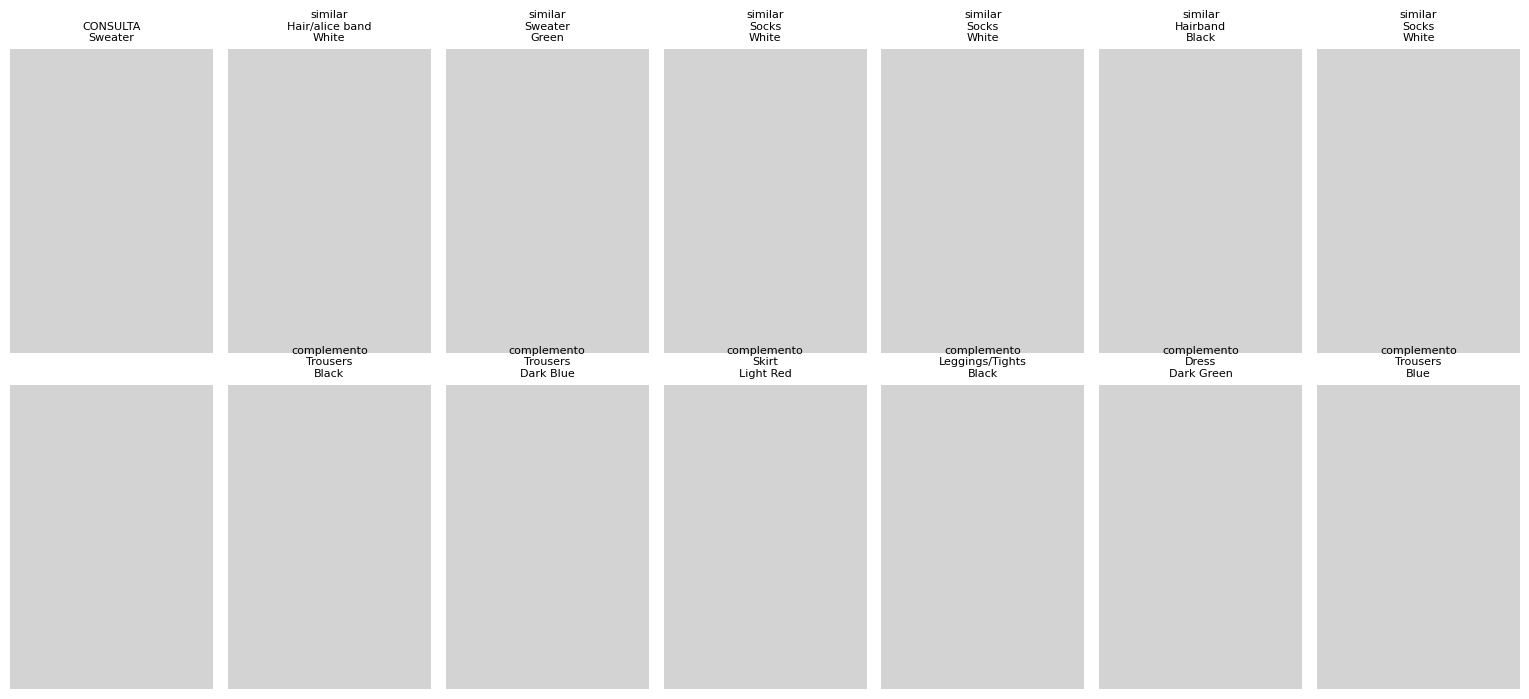

0909370001 ['FF PI Haley dress', 'Dress', 'Off White'] | latencia (ms): {'embedding': 117.4, 'búsqueda': 4.9, 'complementos': 116.6, 'ranking': 47.7}


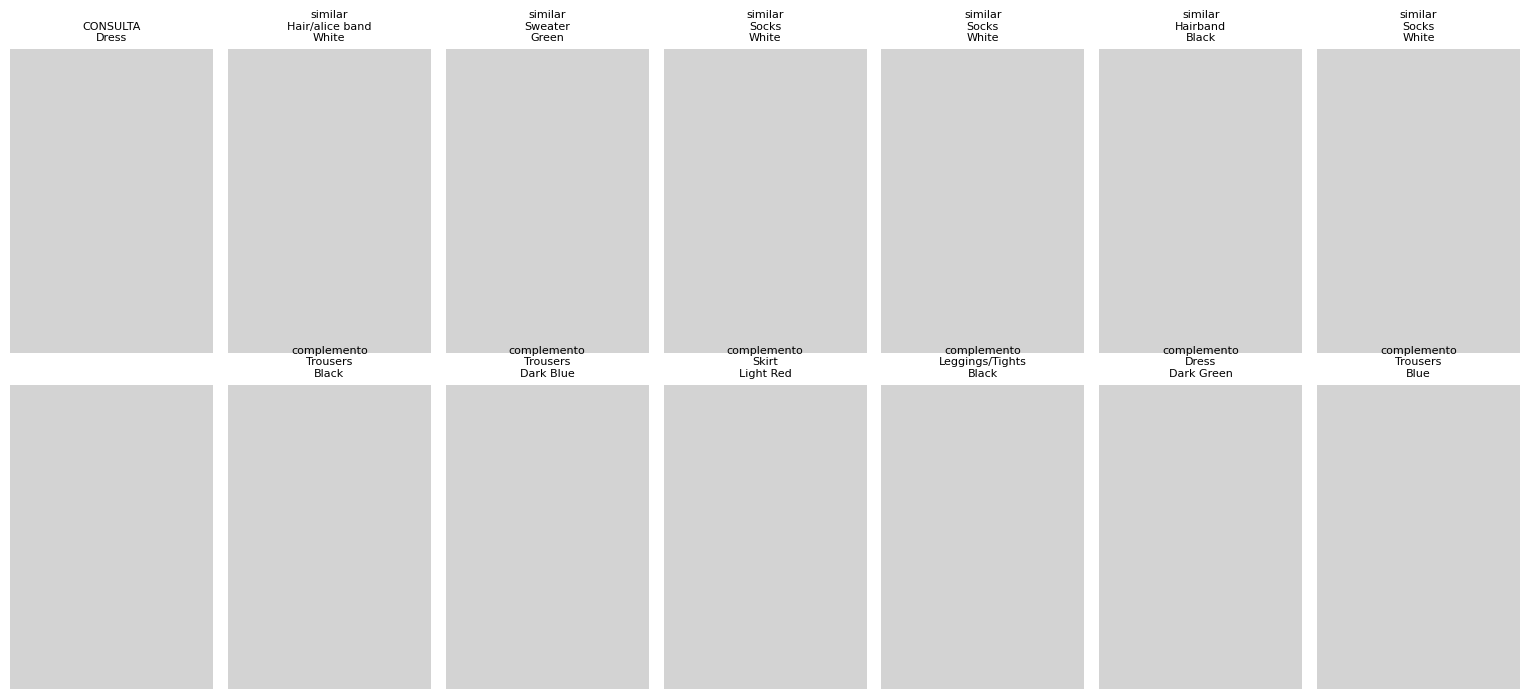

0909320002 ['Key chelsea boot', 'Boots', 'Black'] | latencia (ms): {'embedding': 114.5, 'búsqueda': 5.0, 'complementos': 114.5, 'ranking': 49.0}


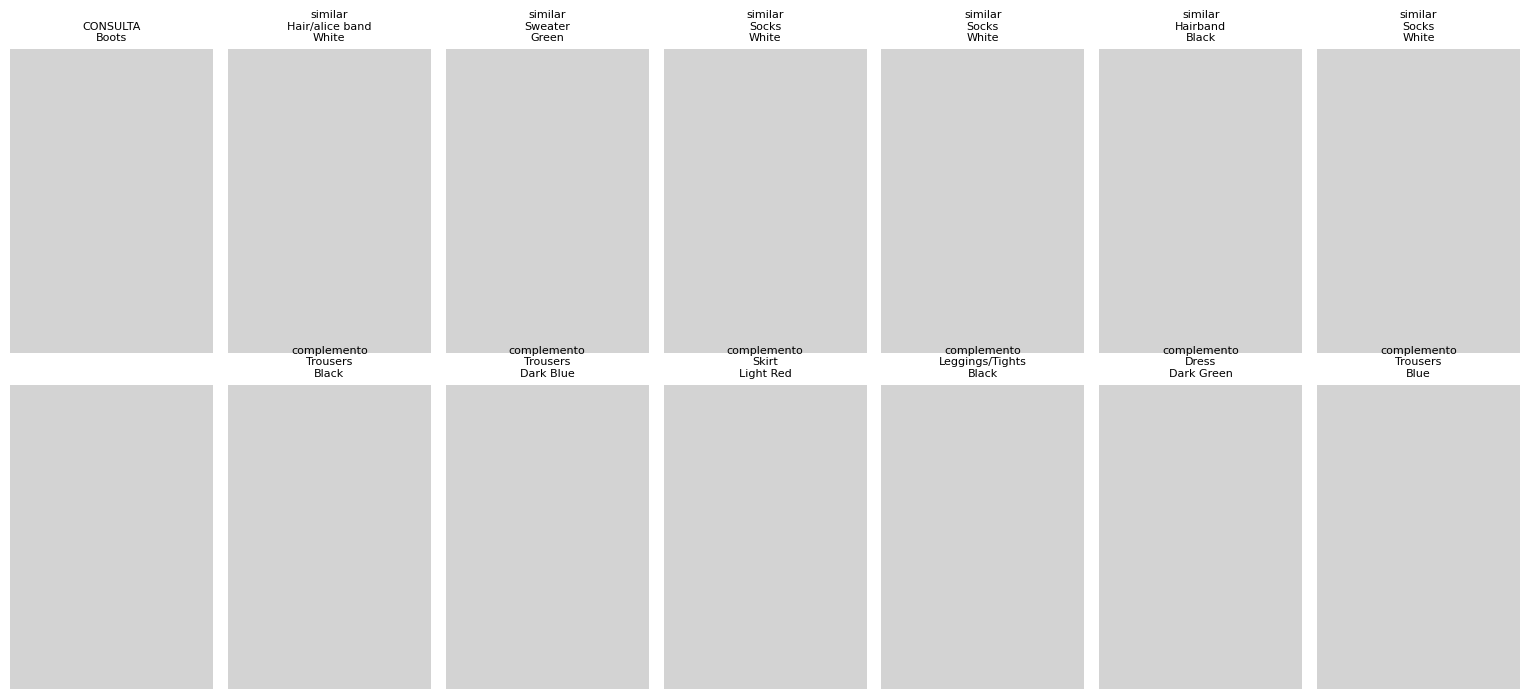

In [12]:
def img_path(aid):
    return DATA / "images" / aid[:3] / f"{aid}.jpg"

def show(res, query_img=None, title=""):
    rows = [("similar", res[res.tipo == "similar"]), ("complemento", res[res.tipo == "complemento"])]
    n = max(len(r) for _, r in rows) + (query_img is not None)
    fig, axes = plt.subplots(2, n, figsize=(2.2 * n, 7))
    for ax in axes.ravel(): ax.axis("off")
    for r, (tipo, d) in enumerate(rows):
        off = 0
        if query_img is not None:
            axes[r, 0].imshow(query_img); axes[r, 0].set_title(f"CONSULTA\n{title}" if r == 0 else "", fontsize=8); off = 1
        for j, x in enumerate(d.itertuples()):
            p = img_path(x.article_id)
            axes[r, j + off].imshow(Image.open(p) if p.exists() else Image.new("RGB", (100, 150), "lightgray"))
            axes[r, j + off].set_title(f"{tipo}\n{x.product_type_name}\n{x.colour_group_name}", fontsize=8)
    plt.tight_layout(); plt.show()

def placeholder(aid):
    p = img_path(aid)
    return Image.open(p) if p.exists() else Image.new("RGB", (100, 150), "lightgray")

by_pop = AVAIL[np.argsort(-POP[AVAIL])]   # el artículo más vendido de cada grupo como "foto subida"
examples = [AID[by_pop[np.argmax(PGROUP[by_pop] == g)]] for g in ["Garment Upper body", "Garment Full body", "Shoes"]]
for aid in examples:
    res, lat = recommend(image=placeholder(aid))
    print(aid, articles.set_index("article_id").loc[aid, ["prod_name", "product_type_name", "colour_group_name"]].tolist(),
          "| latencia (ms):", {k: round(1000 * v, 1) for k, v in lat.items()})
    show(res, placeholder(aid), articles.set_index("article_id").loc[aid, "product_type_name"])

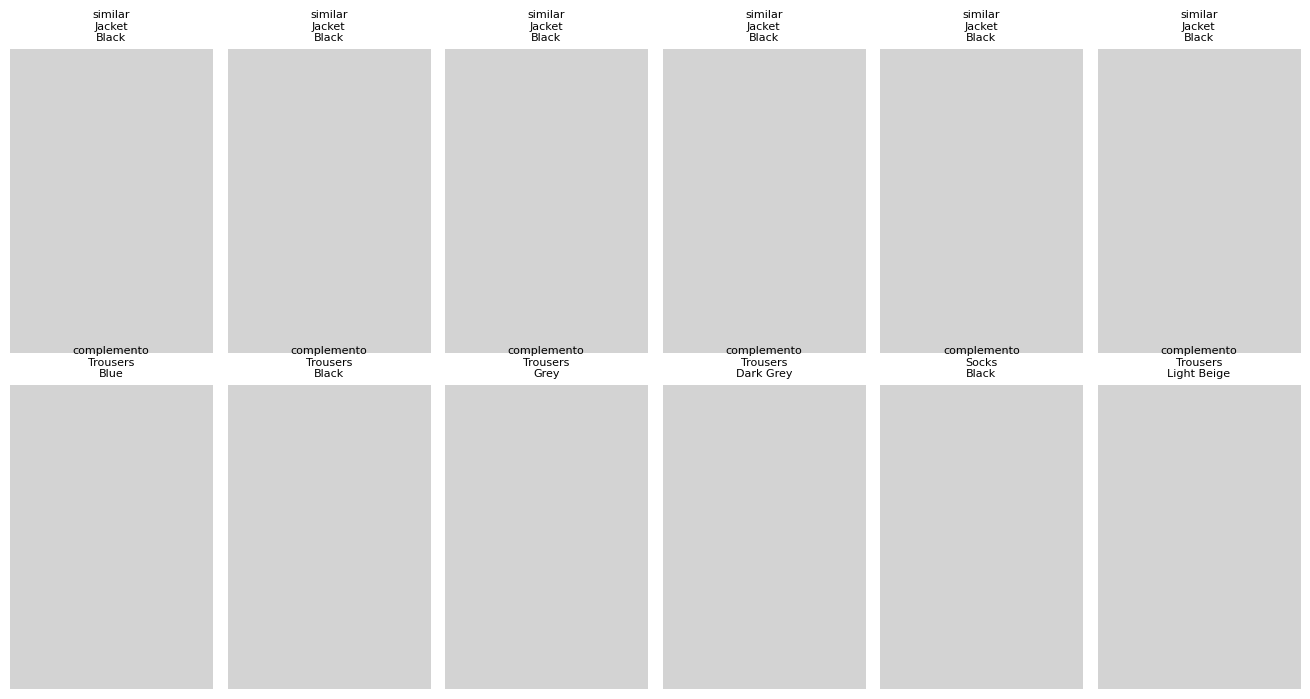

,tipo,article_id,prod_name,product_type_name,colour_group_name,score,sim,cop,ancla
0,similar,0882357001,CEMENT LEATHER BIKER,Jacket,Black,1.000078,0.329549,NaN,None
1,similar,0634744010,Max racer jacket,Jacket,Black,0.950726,0.320940,NaN,None
2,similar,0783126001,Torman jacket,Jacket,Black,0.915738,0.315055,NaN,None
3,similar,0664904001,Torman PU jacket,Jacket,Black,0.906954,0.313544,NaN,None
4,similar,0821118004,max suede,Jacket,Black,0.719057,0.281183,NaN,None
5,similar,0686585008,Kent,Jacket,Black,0.674109,0.273478,NaN,None
6,complemento,0720504010,Skinny 5pkt Lowprice,Trousers,Blue,1.009119,NaN,0.079134,0882357001
7,complemento,0636207006,Slim 5pkt Lowprice,Trousers,Black,0.515582,NaN,0.046669,0882357001
8,complemento,0763988004,DOMINIC SWEATPANT,Trousers,Grey,0.443608,NaN,0.041934,0882357001
9,complemento,0730863043,Skinny 5pkt Midprice,Trousers,Dark Grey,0.361352,NaN,0.036523,0882357001


In [13]:
res, lat = recommend(text="a black leather jacket", filters={"index_group_name": ["Menswear"]})
show(res, title="texto")
res[["tipo", "article_id", "prod_name", "product_type_name", "colour_group_name", "score", "sim", "cop", "ancla"]]

Refinamiento estilo chat: la misma foto + *"red"* (imagen + texto), y la misma foto con un filtro de color explícito.

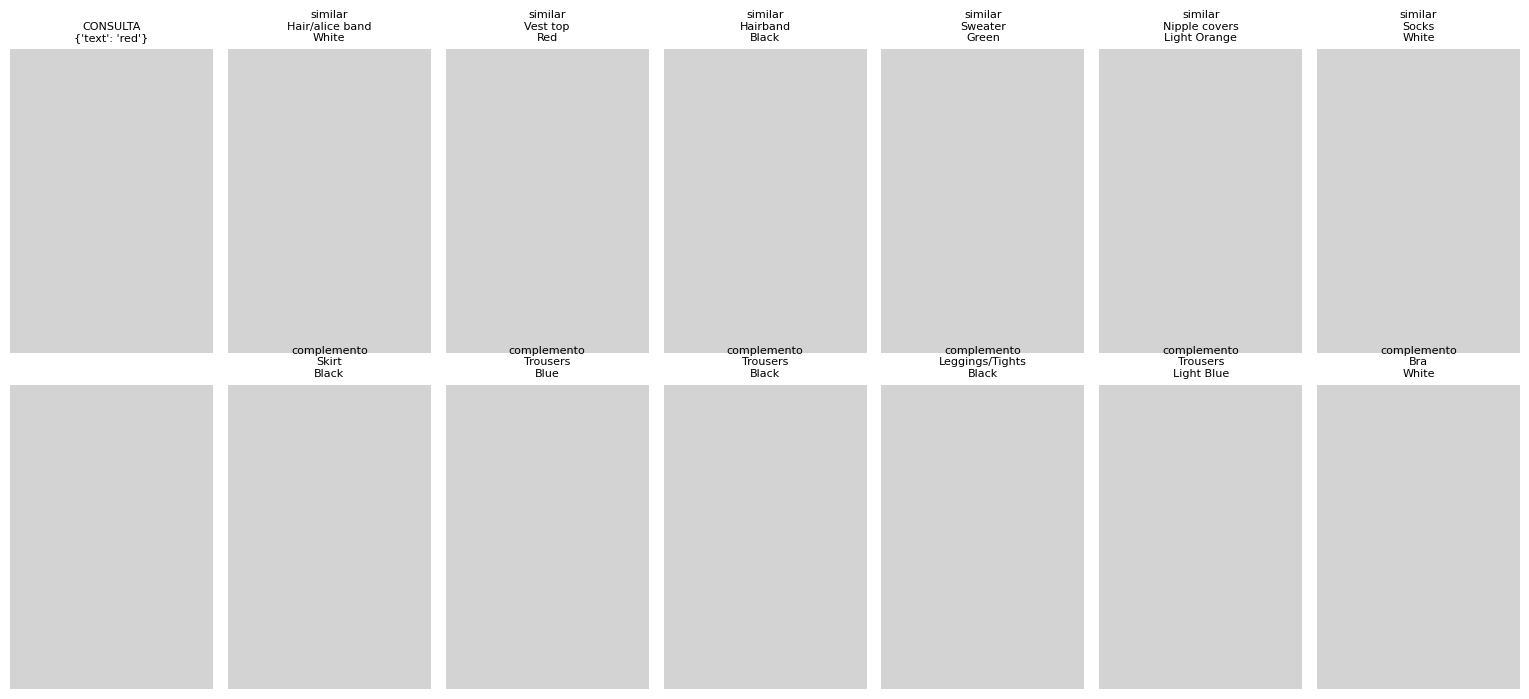

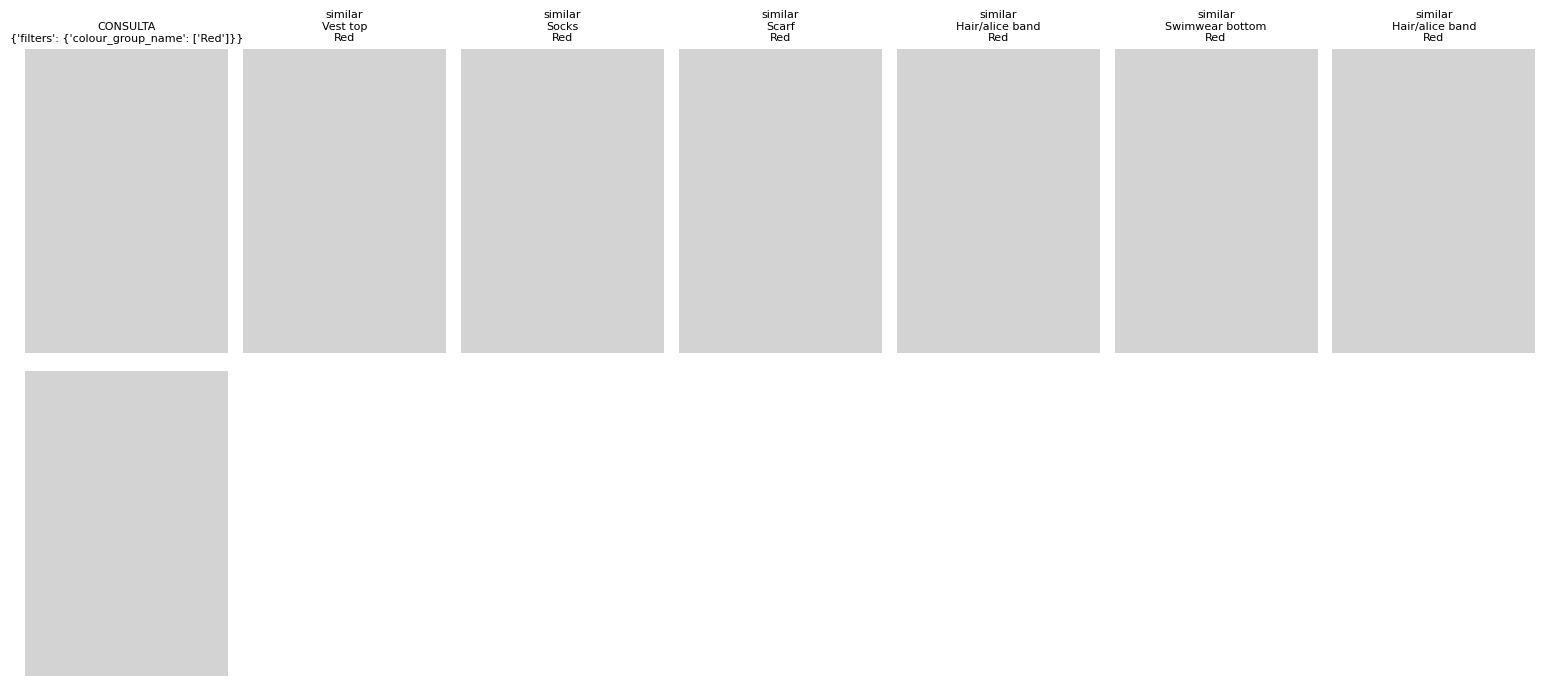

In [14]:
aid = examples[1]
for kw in [dict(text="red"), dict(filters={"colour_group_name": ["Red"]})]:
    res, _ = recommend(image=placeholder(aid), **kw)
    show(res, placeholder(aid), str(kw))

### Latencia y umbral "fuera de catálogo"
La similitud máxima sirve para detectar imágenes que no son ropa o prendas sin equivalente en el catálogo:
comparamos una prenda real del catálogo contra imágenes de ruido.

In [15]:
lat_all = pd.DataFrame([recommend(image=placeholder(a))[1] for a in AID[AVAIL[:20]]]) * 1000
print("Latencia media por etapa (ms):"); print(lat_all.mean().round(1).to_string())

rng = np.random.default_rng(0)
noise = [Image.fromarray(rng.integers(0, 255, (300, 200, 3), dtype=np.uint8)) for _ in range(5)]
print("Similitud máxima · prendas del catálogo:",
      np.round([float((E_AVAIL @ embed_query(placeholder(a))).max()) for a in AID[AVAIL[:5]]], 3))
print("Similitud máxima · ruido:", np.round([float((E_AVAIL @ embed_query(n)).max()) for n in noise], 3))

Latencia media por etapa (ms):
embedding       112.5
búsqueda          5.2
complementos    113.4
ranking          49.1
Similitud máxima · prendas del catálogo: [0.72 0.72 0.72 0.72 0.72]
Similitud máxima · ruido: [0.724 0.726 0.704 0.706 0.717]


# pd.DataFrame({"article_id": AID[AVAIL], "pop": POP[AVAIL]}).to_parquet(OUT / "available.parquet")
print(os.listdir(OUT))